In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.formula.api import ols
import math

df = pd.DataFrame({
    'Temperature': [10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32],
    'Efficiency': [54, 62, 70, 76, 82, 85, 87, 86, 83, 78, 72, 64]
})

df.head()

,Temperature,Efficiency
0,10,54
1,12,62
2,14,70
3,16,76
4,18,82


c:\Users\matth\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=12 observations were given.
  return hypotest_fun_in(*args, **kwds)


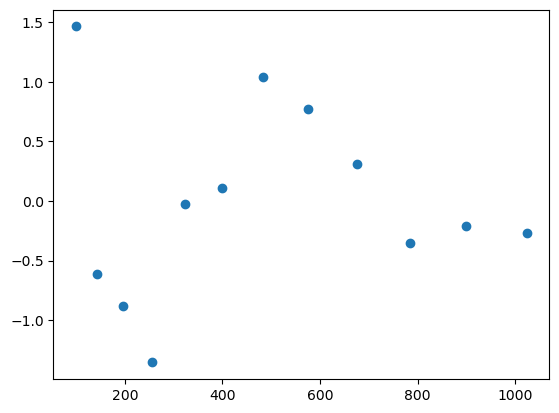

In [23]:
# oefenen polynomiaal
df['Temperature_sq'] = df['Temperature']**2
y = df['Efficiency']

X = df[['Temperature', 'Temperature_sq' ]]
X = sm.add_constant(X)
y = df['Efficiency']

model = sm.OLS(y, X).fit()
model.summary()

prediction = model.get_prediction(pd.DataFrame({'a': [1],'b':[25],'c': [25**2]}))
prediction.summary_frame(alpha = 0.05)
residual = model.resid
plt.scatter(df['Temperature_sq'], residual)

In [27]:
# oefenen opdarcht dummy 

import pandas as pd

df = pd.DataFrame({
    'Experience': [1, 3, 5, 7, 2, 4, 6, 8, 10, 12, 1, 3, 5, 7, 9, 11],
    'Education': ['HBO', 'WO', 'HBO', 'WO', 'WO', 'HBO', 'WO', 'HBO',
                  'WO', 'HBO', 'HBO', 'WO', 'WO', 'HBO', 'WO', 'HBO'],
    'Gender': ['Male', 'Female', 'Female', 'Male', 'Male', 'Female',
               'Female', 'Male', 'Male', 'Female', 'Female', 'Male',
               'Male', 'Female', 'Female', 'Male'],
    'Salary': [2850, 3450, 3550, 4300, 3200, 3300, 4050, 4100,
               4900, 4750, 2900, 3500, 3900, 3950, 4700, 4650]
})

df.head()

,Experience,Education,Gender,Salary
0,1,HBO,Male,2850
1,3,WO,Female,3450
2,5,HBO,Female,3550
3,7,WO,Male,4300
4,2,WO,Male,3200


In [36]:
df_ols = df.copy()
df_ols.columns = ['Experience', 'Education', 'Gender', 'Salary']
model = ols('Salary ~ Experience + C(Education)+ C(Gender)', data = df_ols).fit()
model.summary()
pd.get_dummies(df, columns = ['Education','Gender'])

c:\Users\matth\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=16 observations were given.
  return hypotest_fun_in(*args, **kwds)


,Experience,Salary,Education_HBO,Education_WO,Gender_Female,Gender_Male
0,1,2850,True,False,False,True
1,3,3450,False,True,True,False
2,5,3550,True,False,True,False
3,7,4300,False,True,False,True
4,2,3200,False,True,False,True
5,4,3300,True,False,True,False
6,6,4050,False,True,True,False
7,8,4100,True,False,False,True
8,10,4900,False,True,False,True
9,12,4750,True,False,True,False


(0     2625.055522
 1     3329.799512
 2     3374.918956
 3     4091.999222
 4     3155.486228
 5     3187.289193
 6     3891.351572
 7     3938.703816
 8     4644.551100
 9     4666.610101
 10    2619.882240
 11    3344.339154
 12    3719.750424
 13    3747.803634
 14    4446.007397
 15    4490.413244
 Name: obs_ci_lower, dtype: float64,
 0     2989.707877
 1     3679.005027
 2     3710.608209
 3     4428.164969
 4     3500.850826
 5     3525.472545
 6     4235.749249
 7     4285.417575
 8     4993.909374
 9     5028.275057
 10    2974.583215
 11    3684.763327
 12    4054.882912
 13    4083.254387
 14    4799.389706
 15    4852.004429
 Name: obs_ci_upper, dtype: float64)

In [52]:
import pandas as pd

df = pd.DataFrame({
    'BookingID': [101, 102, 103, 104, 104, 105],
    'Age': [25, 34, -5, 42, 29, 17],
    'Price': [120, 150, 200, None, 180, -50],
    'Nights': [2, 3, 5, 4, 0, 2]
})

print(df)

   BookingID  Age  Price  Nights
0        101   25  120.0       2
1        102   34  150.0       3
2        103   -5  200.0       5
3        104   42    NaN       4
4        104   29  180.0       0
5        105   17  -50.0       2


In [82]:
# assert (df['BookingID'].duplicated()).all(), 'dubbele'
# assert (df['Age']>=0).all(), 'foutmelding'
# assert (df['Price'].isna().sum() == 0), 'gozer'
# assert (df['Price']>0).all(), 'gast'
# assert (df['Nights'] >=1).all(), 'eyyy'